<a href="https://colab.research.google.com/github/sanjil18/Churn-app/blob/main/Tabular_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q mlflow

import mlflow
import mlflow.sklearn

# Explicit tracking URI: MLflow's unconfigured default doesn't reliably persist
# run history in this version, and the legacy local ./mlruns folder-based
# tracking store is deprecated. SQLite is MLflow's current recommended
# lightweight backend for local use.
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("telco-churn-prediction")

c:\Users\sanji\AppData\Local\Programs\Python\Python310\lib\site-packages\pydantic\_internal\_fields.py:160: UserWarning: Field "model_name" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
c:\Users\sanji\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/07/23 21:59:36 INFO mlflow.tracking.fluent: Experiment with name 'telco-churn-prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location=('file:///c:/Users/sanji/Desktop/Project of Mine all UG/ML_ AI projects/Churn '
 'app/mlruns/2'), creation_time=1784824176406, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1784824176406, lifecycle_stage='active', name='telco-churn-prediction', tags={}, trace_location=None, workspace='default'>

**Note on MLflow tracking:** this notebook can be run in Google Colab or locally (e.g. WSL). MLflow logs each run to a local `mlruns/` folder in the current working directory. If you run this in Colab, that folder lives on the ephemeral Colab VM and **will not persist** once the session ends — download the `mlruns/` folder before disconnecting, or mount Google Drive (`from google.colab import drive; drive.mount('/content/drive')`) and point `mlflow.set_tracking_uri(...)` at a path under `/content/drive/...` if you want run history to survive across sessions.

In [2]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("model") / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
df.shape
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
pd.to_numeric(df['TotalCharges'], errors='coerce').isna().sum()

np.int64(11)

In [4]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [5]:
df[pd.to_numeric(df['TotalCharges'], errors='coerce').isna()]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [6]:
# Step 1: Convert the column to numeric, forcing the empty spaces (" ") to become NaN (Not a Number)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Step 2: Fill all those NaN values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Optional Step 3: Check if it worked! The result should be 0.
print(df['TotalCharges'].isna().sum())

0


In [7]:
df = df.drop('customerID', axis=1)

In [8]:
print(df.isna().sum())


gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


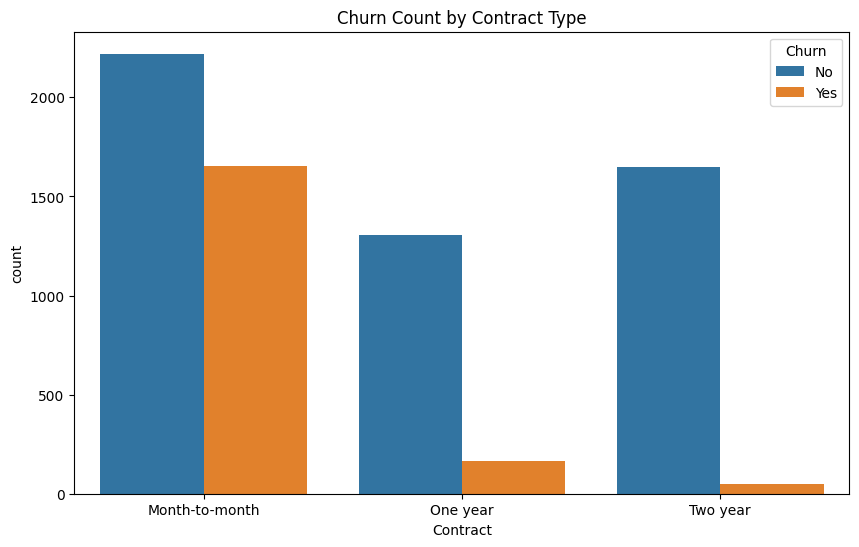

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn Count by Contract Type')
plt.show()

In [11]:

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})


df = pd.get_dummies(df, drop_first=True)


print(df.head())

   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  Churn  gender_Male  \
0              0       1           29.85         29.85      0        False   
1              0      34           56.95       1889.50      0         True   
2              0       2           53.85        108.15      1         True   
3              0      45           42.30       1840.75      0         True   
4              0       2           70.70        151.65      1        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  ...  StreamingTV_No internet service  \
0                            True  ...                            False   
1                           False  ...                            Fa

In [12]:
# 'Churn' (except x)
X = df.drop('Churn', axis=1)

#  Y
y = df['Churn']

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


model = RandomForestClassifier()


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

Model Accuracy: 79.56%


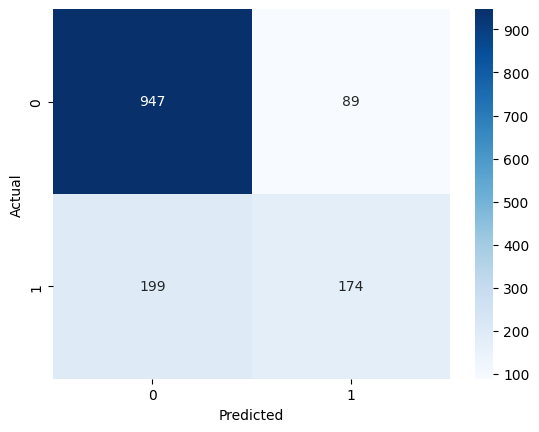

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.47      0.55       373

    accuracy                           0.80      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.80      0.78      1409



In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


print(classification_report(y_test, y_pred))

In [16]:

model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [17]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)


model.fit(X_train_res, y_train_res)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [18]:

model = RandomForestClassifier(class_weight='balanced', random_state=42)


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1036
           1       0.66      0.45      0.54       373

    accuracy                           0.79      1409
   macro avg       0.74      0.68      0.70      1409
weighted avg       0.78      0.79      0.78      1409



In [19]:
from imblearn.over_sampling import SMOTE


smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)


model = RandomForestClassifier(random_state=42)
model.fit(X_train_res, y_train_res)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1036
           1       0.61      0.60      0.61       373

    accuracy                           0.79      1409
   macro avg       0.73      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409



In [20]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    random_state=42
)
model.fit(X_train_res, y_train_res)

RandomForestClassifier(max_depth=10, min_samples_split=5, n_estimators=300,
                       random_state=42)

In [21]:
feature_importances = pd.DataFrame(model.feature_importances_,
                                   index=X_train.columns,
                                   columns=['importance']).sort_values('importance', ascending=False)
print(feature_importances.head(10))

                                importance
tenure                            0.156431
PaymentMethod_Electronic check    0.144661
TotalCharges                      0.130736
MonthlyCharges                    0.081289
InternetService_Fiber optic       0.079227
Contract_Two year                 0.071549
PaperlessBilling_Yes              0.063597
Contract_One year                 0.026695
MultipleLines_No phone service    0.019239
StreamingMovies_Yes               0.019186


In [22]:

from xgboost import XGBClassifier

model = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X_train_res, y_train_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)

In [23]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(RandomForestClassifier(class_weight='balanced'), param_grid, cv=5)
grid_search.fit(X_train_res, y_train_res)
print(grid_search.best_params_)

{'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 300}


In [24]:

best_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=2,
    random_state=42,
    class_weight='balanced'
)


best_model.fit(X_train_res, y_train_res)


y_pred = best_model.predict(X_test)


from sklearn.metrics import classification_report, accuracy_score
print(classification_report(y_test, y_pred))
print(f"Final Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1036
           1       0.60      0.63      0.61       373

    accuracy                           0.79      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.79      0.79      1409

Final Accuracy: 79.06%


In [25]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

with mlflow.start_run(run_name="random-forest-smote-v1"):
    # 1. Pipeline-ஐ சரியாக வடிவமைத்தல்
    # இங்கே SMOTE மற்றும் Model ஆகியவற்றை இணைக்கிறோம்
    pipeline = Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('model', RandomForestClassifier(n_estimators=500, max_depth=15, min_samples_split=2, random_state=42))
    ])

    # 2. கவனிக்கவும்: நாம் ஒரிஜினல் X_train, y_train-ஐ மட்டுமே பயன்படுத்துகிறோம்!
    # Pipeline உள்ளே இருக்கும் SMOTE தானாகவே ட்ரெய்னிங் டேட்டாவை மட்டும் மாற்றும்.
    pipeline.fit(X_train, y_train)

    # 3. கணித்தல்
    y_pred = pipeline.predict(X_test)

    # 4. முடிவு
    print(classification_report(y_test, y_pred))

    # MLflow: log the actual hyperparameters used by the fitted RandomForestClassifier
    rf_step = pipeline.named_steps['model']
    mlflow.log_params({
        "n_estimators": rf_step.n_estimators,
        "max_depth": rf_step.max_depth,
        "min_samples_split": rf_step.min_samples_split,
        "random_state": rf_step.random_state,
        "resampling": "SMOTE",
    })

    # MLflow: log test-set evaluation metrics
    mlflow.log_metrics({
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
    })

    # MLflow: log the trained pipeline itself as a model artifact
    mlflow.sklearn.log_model(
        pipeline,
        "model",
        skops_trusted_types=[
            "imblearn.over_sampling._smote.base.SMOTE",
            "imblearn.pipeline.Pipeline",
        ],
    )

              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1036
           1       0.60      0.63      0.61       373

    accuracy                           0.79      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.79      0.79      1409



2026/07/23 22:07:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [26]:
# மாடல் கணித்த நிகழ்தகவு (Probability)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# த்ரெஷோல்ட் 0.5-க்கு பதிலாக 0.4 என்று வைப்போம்
# அதாவது 40% சந்தேகம் இருந்தாலே அது 'Yes' என எடுத்துக்கொள்ளும்
y_pred_new = (y_prob > 0.4).astype(int)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_new))

              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1036
           1       0.55      0.74      0.63       373

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



In [27]:
import joblib
from pathlib import Path


MODEL_DIR = Path("model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, MODEL_DIR / "churn_model.joblib")
print("மாடல் வெற்றிகரமாகச் சேமிக்கப்பட்டது!")

மாடல் வெற்றிகரமாகச் சேமிக்கப்பட்டது!


## Performance summary

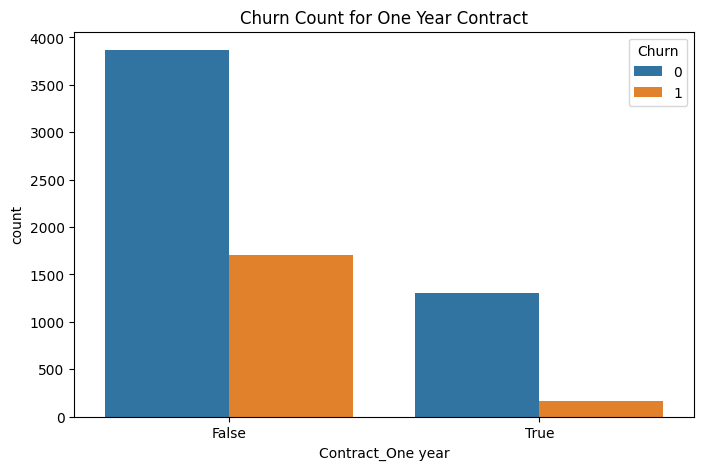

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# `Contract` காலம் இப்போது இருக்காது, அதனால் அதற்குப் பதிலாக
# dummy variables-ஐப் பயன்படுத்தி வரைபடம் வரையலாம்:

# உதாரணம்: 'Contract_One year' மற்றும் 'Churn' ஆகியவற்றைப் பார்ப்போம்
sns.countplot(x='Contract_One year', hue='Churn', data=df)
plt.title('Churn Count for One Year Contract')
plt.show()

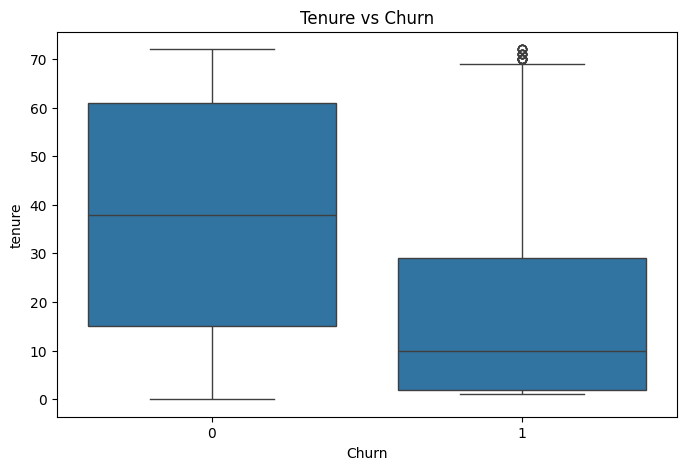

In [29]:
# Tenure vs Churn
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tenure vs Churn')
plt.show()

In [30]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1036
           1       0.60      0.63      0.61       373

    accuracy                           0.79      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.79      0.79      1409

